# Phase 3: Graph Construction: From Structures to PAE-Weighted Protein Graphs
This notebook turns each protein's AlphaFold structure into a graph the GNN can learn from, and attaches each ClinVar variant as a labelled training sample on that graph.

**In one sentence:** each protein becomes a network where every amino acid is a node, two amino acids are connected if they sit close together in the folded 3D structure, and each connection is weighted by how *confident* AlphaFold is about that pair's relative position (the PAE-weighting that is this project's core novel idea).

**Inputs:** `clinvar_with_structures.csv`, `alphafold_data/pdb/*.pdb`, `alphafold_data/pae/*.json`, `alphafold_data/metadata/*.json` (all from Phase 2)

**Outputs:**
- `esm2_embeddings/{UniProt_ID}.npy` - per-protein evolutionary embeddings (one row per residue)
- `protein_graphs/{UniProt_ID}.pt` - one cached structural graph per protein (shared by all its variants)
- `phase3_graph_manifest.csv` - per-protein status log for this phase
- `clinvar_graph_ready.csv` - final variant table, restricted to variants whose protein graph built successfully
- A `MissenseVariantGraphDataset` class (PyTorch Geometric `Dataset`) that turns each row of that table into a labelled training graph on demand - this is the object Phase 4 (model training) will load directly.

**Key sources:**
- Jumper, J. et al. (2021). *Highly accurate protein structure prediction with AlphaFold.* Nature, 596, 583–589. [doi:10.1038/s41586-021-03819-2](https://doi.org/10.1038/s41586-021-03819-2) - defines the Predicted Aligned Error (PAE) we use as edge weights.
- Lin, Z. et al. (2023). *Evolutionary-scale prediction of atomic-level protein structure with a language model.* Science, 379(6637), 1123–1130. [doi:10.1126/science.ade2574](https://doi.org/10.1126/science.ade2574) - the ESM-2 protein language model used for node features.
- Gligorijević, V. et al. (2021). *Structure-based protein function prediction using graph convolutional networks.* Nature Communications, 12, 3168. [doi:10.1038/s41467-021-23303-9](https://doi.org/10.1038/s41467-021-23303-9) - representative use of a Cα distance cutoff to define a residue contact graph, the convention we follow for edges.
- Fey, M. & Lenssen, J.E. (2019). *Fast Graph Representation Learning with PyTorch Geometric.* ICLR Workshop on Representation Learning on Graphs and Manifolds. [arXiv:1903.02428](https://arxiv.org/abs/1903.02428) - the graph deep learning library we build on.

In [2]:
import os
import json
import gc
from collections import OrderedDict
import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data, Dataset
from Bio.PDB import PDBParser
import warnings
from Bio import BiopythonWarning
from tqdm.notebook import tqdm
warnings.simplefilter("ignore", BiopythonWarning)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load Phase 2 Output
We work from `clinvar_with_structures.csv`, every variant here already has a confirmed AlphaFold structure and PAE matrix (Phase 2), and has passed two independent reference-amino-acid checks (Phase 1 + Phase 2). Phase 3 adds a *third* layer of validation specific to graph-building, in Section 4, because it works directly off the raw structure/PAE files rather than their summary metadata.

In [3]:
df = pd.read_csv("clinvar_with_structures.csv")
print(f"Variants carried into Phase 3 : {len(df):,}")
print(f"Unique proteins                : {df['UniProt_ID'].nunique():,}")
print(f"  Pathogenic (1): {(df['Target']==1).sum():,}")
print(f"  Benign     (0): {(df['Target']==0).sum():,}")

BASE_DIR = "alphafold_data"
PDB_DIR = os.path.join(BASE_DIR, "pdb")
PAE_DIR = os.path.join(BASE_DIR, "pae")
META_DIR = os.path.join(BASE_DIR, "metadata")

ESM2_DIR = "esm2_embeddings"
GRAPH_DIR = "protein_graphs"
os.makedirs(ESM2_DIR, exist_ok=True)
os.makedirs(GRAPH_DIR, exist_ok=True)

unique_proteins = sorted(df["UniProt_ID"].unique().tolist())

Variants carried into Phase 3 : 49,303
Unique proteins                : 6,597
  Pathogenic (1): 20,151
  Benign     (0): 29,152


## 2. Node Features, Part 1: ESM-2 Evolutionary Embeddings
### What ESM-2 is, in plain terms
ESM-2 is a language model, the same kind of architecture as a text-generation AI, but instead of being trained on English sentences, it was trained on millions of real protein sequences from across all known life. By learning to predict 'what amino acid usually appears here, given the rest of the sequence', it implicitly learns which positions in a protein are evolutionarily constrained (changing them is usually harmful and rarely tolerated across species) versus tolerant of substitution (changing them is usually harmless). For every amino acid, ESM-2 outputs a vector of numbers (an *embedding*) summarising this learned context, we use this as a primary feature for every node in our graph.

### Why include this at all, given we already have the 3D structure?
The 3D structure tells the GNN about a position's *spatial* role (what's physically nearby). ESM-2 tells it about a position's *evolutionary* role (how tolerant this exact spot has historically been to change, based on patterns across millions of related sequences). These are complementary signals, and combining structure-based and sequence/evolutionary-based features is standard practice in modern variant-effect predictors, including AlphaMissense (Cheng et al., 2023, [doi:10.1126/science.adg7492](https://doi.org/10.1126/science.adg7492)) and gMVP (Ye et al., 2023, [doi:10.1038/s41467-023-42940-8](https://doi.org/10.1038/s41467-023-42940-8)).

### Model choice
We use `facebook/esm2_t33_650M_UR50D`, 650 million parameters, 33 transformer layers, producing a 1280-dimensional embedding per residue. This is a mid-sized ESM-2 checkpoint: large enough to capture rich evolutionary signal, small enough to run on a single consumer GPU (RTX 4050, 6 GB VRAM) one protein at a time.

In [4]:
from transformers import AutoTokenizer, AutoModel

ESM2_MODEL_NAME = "facebook/esm2_t33_650M_UR50D"
ESM2_EMBEDDING_DIM = 1280

print(f"Loading {ESM2_MODEL_NAME}...")
esm2_tokenizer = AutoTokenizer.from_pretrained(ESM2_MODEL_NAME)
esm2_model = AutoModel.from_pretrained(ESM2_MODEL_NAME)
esm2_model.eval()
esm2_model.to(DEVICE)
print("ESM-2 ready.")

Loading facebook/esm2_t33_650M_UR50D...


Loading weights:   0%|          | 0/534 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t33_650M_UR50D
Key                       | Status     | 
--------------------------+------------+-
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.weight       | MISSING    | 
pooler.dense.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


ESM-2 ready.


## 3. Generate & Cache ESM-2 Embeddings (One Run Per Unique Protein)
Each protein's sequence is run through ESM-2 exactly **once**, regardless of how many variants it has, embeddings are cached to disk (`esm2_embeddings/{UniProt_ID}.npy`) and reused for every variant on that protein.

We use the canonical sequence cached in Phase 2's metadata (`uniprotSequence`), i.e. the sequence AlphaFold itself modelled, not a fresh UniProt fetch to guarantee the embedding's positions line up exactly with the structure's residue numbering.

**GPU memory handling:** ESM-2's memory use grows roughly with the square of sequence length (self-attention). We process one protein at a time in half precision (fp16) and fall back to CPU for any single protein that runs out of GPU memory, rather than letting one large protein crash the whole batch.

**Validation:** after stripping the model's special start/end tokens, the number of embedding rows must exactly equal the protein's sequence length. Any mismatch is logged and that protein is excluded, this is a hard requirement, since a one-position offset here would silently scramble every node's identity in the graph.

In [5]:
def get_esm2_embedding(sequence, uniprot_id):
    """
    Returns (embedding_array, status) where embedding_array has shape (len(sequence), 1280),
    or (None, status) on failure. status in: 'cached', 'success', 'length_mismatch', 'failed'
    """
    cache_path = os.path.join(ESM2_DIR, f"{uniprot_id}.npy")
    if os.path.exists(cache_path):
        return np.load(cache_path), "cached"

    try:
        inputs = esm2_tokenizer(sequence, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            with torch.autocast(device_type=DEVICE if DEVICE == "cuda" else "cpu", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                out = esm2_model(**inputs)
        # Strip <cls> (first) and <eos> (last) tokens to get one row per real residue
        emb = out.last_hidden_state[0, 1:-1, :].float().cpu().numpy()
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        try:
            inputs = esm2_tokenizer(sequence, return_tensors="pt")  # CPU fallback
            with torch.no_grad():
                out = esm2_model.to("cpu")(**inputs)
            emb = out.last_hidden_state[0, 1:-1, :].float().numpy()
            esm2_model.to(DEVICE)  # restore for next protein
        except Exception:
            return None, "failed"
    except Exception:
        return None, "failed"

    if emb.shape[0] != len(sequence):
        return None, "length_mismatch"

    np.save(cache_path, emb)
    return emb, "success"

In [ ]:
esm2_status = {}
sequence_cache = {}

for uid in tqdm(unique_proteins, desc="ESM-2 embeddings"):
    meta_path = os.path.join(META_DIR, f"{uid}.json")
    if not os.path.exists(meta_path):
        esm2_status[uid] = "missing_metadata"
        continue
    with open(meta_path, "r") as f:
        entry = json.load(f)
    seq = entry["uniprotSequence"]
    sequence_cache[uid] = seq

    _, status = get_esm2_embedding(seq, uid)
    esm2_status[uid] = status

    if DEVICE == "cuda" and len(seq) > 1000:
        torch.cuda.empty_cache()  # be conservative with VRAM for large proteins

esm2_status_series = pd.Series(esm2_status)
print("\n=== ESM-2 embedding status ===")
print(esm2_status_series.value_counts().to_string())

# Free GPU memory, ESM-2 is not needed again after this point
del esm2_model
gc.collect()
if DEVICE == "cuda":
    torch.cuda.empty_cache()

ESM-2 embeddings:   0%|          | 0/6597 [00:00<?, ?it/s]


=== ESM-2 embedding status ===
success    6596
cached        1


## 4. Node Features, Part 2 & Edges: The Structural Contact Graph
### Turning a 3D structure into a graph
We treat each amino acid (residue) as a **node**. Two nodes get an **edge** between them if their Cα atoms, the central 'backbone' atom of each amino acid, standard for representing residue position are within **8 Å** of each other in the folded 3D structure. This distance-cutoff contact graph is a widely used convention for representing protein structure as a graph for deep learning (e.g. Gligorijević et al., 2021, [doi:10.1038/s41467-021-23303-9](https://doi.org/10.1038/s41467-021-23303-9)). Intuitively: two amino acids that are close together in the folded protein can physically interact (e.g. forming part of the same binding pocket or structural core) even if they are far apart in the linear sequence, this is exactly the information a graph adds beyond a flat sequence.

### Why weight edges by PAE, the project's central novel idea
A binary 'are they within 8Å, yes or no' edge treats AlphaFold's prediction as ground truth with uniform confidence everywhere. In reality, AlphaFold reports, for every *pair* of residues, a **Predicted Aligned Error (PAE)**, its own estimate (in Ångströms) of how wrong the relative position of that pair might be (Jumper et al., 2021). A low PAE means 'I am confident these two residues are positioned correctly relative to each other'; a high PAE means 'treat this pair's relative position with caution, often this happens between separate domains that move relative to one another, or in flexible linker regions'.

Existing structure-based variant-effect GNNs (e.g. gMVP) use unweighted contact graphs, every edge counts equally. We instead convert each pair's PAE into an edge weight:

```
edge_weight = 1 / (1 + average(PAE[i][j], PAE[j][i]))
```

PAE is averaged across both directions because AlphaFold's PAE matrix is not symmetric (the error estimate from residue i's frame looking at j is not identical to j looking at i). The `1/(1+x)` transform maps PAE (0 Å = 'perfectly confident' upward, unbounded) onto a bounded (0, 1] weight where 1 = maximum confidence and the weight shrinks smoothly as uncertainty grows. This lets the GNN learn to down-weight messages passed along structurally uncertain connections, rather than trusting every contact in the structure equally, this PAE-weighting is what distinguishes our approach from a standard contact-graph GNN.

### Per-protein validation before building any graph
Before constructing a graph, we require **four independent counts to agree exactly**: the number of residues with a Cα atom in the PDB file, the length of the canonical sequence from Phase 2's metadata, the dimension of the PAE matrix, and the length of the cached ESM-2 embedding. If any of these disagree, the protein is excluded rather than guessed at; a silent off-by-one here would misassign every node's identity and corrupt every variant built on that protein's graph.

In [7]:
DISTANCE_CUTOFF_ANGSTROM = 8.0
AA_3TO1 = {
    'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E','GLY':'G','HIS':'H','ILE':'I',
    'LEU':'L','LYS':'K','MET':'M','PHE':'F','PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'
}
AA_1TO_ONEHOT_IDX = {aa: i for i, aa in enumerate(sorted(AA_3TO1.values()))}
N_AA = len(AA_1TO_ONEHOT_IDX)  # 20

pdb_parser = PDBParser(QUIET=True)

def extract_ca_coords_and_sequence(uniprot_id):
    """Returns (ca_coords: dict[resnum -> xyz], seq_from_pdb: str) ordered by residue number."""
    pdb_path = os.path.join(PDB_DIR, f"{uniprot_id}.pdb")
    structure = pdb_parser.get_structure(uniprot_id, pdb_path)
    ca_coords = {}
    resnames = {}
    for model in structure:
        for chain in model:
            for residue in chain:
                if residue.get_id()[0] != ' ':
                    continue  # skip heteroatoms/waters
                ca_atoms = [a for a in residue if a.get_id() == 'CA']
                if ca_atoms:
                    resnum = residue.get_id()[1]
                    ca_coords[resnum] = ca_atoms[0].get_coord()
                    resnames[resnum] = AA_3TO1.get(residue.get_resname(), 'X')
        break  # single-chain monomer models
    return ca_coords, resnames

In [ ]:
def build_protein_graph(uniprot_id):
    """
    Builds and caches one structural graph for a protein.
    Returns status string: 'cached', 'success', or a specific failure reason.
    """
    graph_path = os.path.join(GRAPH_DIR, f"{uniprot_id}.pt")
    if os.path.exists(graph_path):
        return "cached"

    if esm2_status.get(uniprot_id) not in ("cached", "success"):
        return "no_esm2_embedding"

    pae_path = os.path.join(PAE_DIR, f"{uniprot_id}.json")
    meta_path = os.path.join(META_DIR, f"{uniprot_id}.json")
    pdb_path = os.path.join(PDB_DIR, f"{uniprot_id}.pdb")
    if not (os.path.exists(pae_path) and os.path.exists(meta_path) and os.path.exists(pdb_path)):
        return "missing_input_file"

    with open(meta_path, "r") as f:
        canonical_seq = json.load(f)["uniprotSequence"]
    with open(pae_path, "r") as f:
        pae_matrix = np.array(json.load(f)[0]["predicted_aligned_error"], dtype=np.float32)

    ca_coords, resnames_from_pdb = extract_ca_coords_and_sequence(uniprot_id)
    esm2_emb = np.load(os.path.join(ESM2_DIR, f"{uniprot_id}.npy"))

    # --- 4-way consistency check: PDB residues == canonical sequence == PAE matrix == ESM-2 embedding ---
    n_pdb = len(ca_coords)
    n_seq = len(canonical_seq)
    n_pae = pae_matrix.shape[0]
    n_esm = esm2_emb.shape[0]
    if not (n_pdb == n_seq == n_pae == n_esm):
        return f"length_mismatch (pdb={n_pdb}, seq={n_seq}, pae={n_pae}, esm2={n_esm})"
    if set(ca_coords.keys()) != set(range(1, n_pdb + 1)):
        return "non_contiguous_residue_numbering"

    # --- Build edges: Cα-Cα distance < cutoff ---
    coords = np.stack([ca_coords[i] for i in range(1, n_pdb + 1)])  # shape (N, 3), ordered by residue number
    diff = coords[:, None, :] - coords[None, :, :]
    dist_matrix = np.sqrt((diff ** 2).sum(-1))
    np.fill_diagonal(dist_matrix, np.inf)  # no self-loops
    contact_mask = dist_matrix < DISTANCE_CUTOFF_ANGSTROM
    src, dst = np.where(contact_mask)

    distances = dist_matrix[src, dst]
    pae_sym = (pae_matrix[src, dst] + pae_matrix[dst, src]) / 2.0
    pae_weight = 1.0 / (1.0 + pae_sym)

    edge_index = torch.tensor(np.stack([src, dst]), dtype=torch.long)
    edge_attr = torch.tensor(np.stack([distances, pae_weight], axis=1), dtype=torch.float)  # [distance, pae_weight]

    # --- Node features: ESM-2 embedding (1280) + wild-type AA one-hot (20) + 21 zero placeholder columns ---
    # The 21 placeholder columns (1 variant-flag + 20 alt-AA one-hot) are filled in per-variant at load time
    # by MissenseVariantGraphDataset (Section 6), they stay zero in this shared base graph.
    wt_onehot = np.zeros((n_pdb, N_AA), dtype=np.float32)
    for i in range(n_pdb):
        aa = canonical_seq[i]
        if aa in AA_1TO_ONEHOT_IDX:
            wt_onehot[i, AA_1TO_ONEHOT_IDX[aa]] = 1.0
    placeholder = np.zeros((n_pdb, 1 + N_AA), dtype=np.float32)
    x = np.concatenate([esm2_emb, wt_onehot, placeholder], axis=1)

    data = Data(
        x=torch.tensor(x, dtype=torch.float),
        edge_index=edge_index,
        edge_attr=edge_attr,
        uniprot_id=uniprot_id,
        num_residues=n_pdb,
    )
    torch.save(data, graph_path)
    return "success"

## 5. Run Batch Graph Construction

In [9]:
graph_status = {}
for uid in tqdm(unique_proteins, desc="Building protein graphs"):
    graph_status[uid] = build_protein_graph(uid)

graph_status_series = pd.Series(graph_status)
print("\n=== Protein graph construction status ===")
print(graph_status_series.value_counts().to_string())

Building protein graphs:   0%|          | 0/6597 [00:00<?, ?it/s]


=== Protein graph construction status ===
success    6596
cached        1


## 6. From Protein Graphs to Labelled Variant Samples
### Why one shared graph per protein, not one graph per variant
A protein's structure and edges never change between its variants, only the GNN's *input signal at one node* changes, the location and identity of the substitution. Saving a full duplicate graph per variant would multiply disk usage by the number of variants per protein for no benefit (BRCA1 alone has 318 variants sharing one 1,863-residue structure). Instead we cache the structure once (Section 5) and apply two small, cheap edits to a copy of its node features at load time:

1. **Variant-site flag**: set to `1` only at the mutated residue's node, `0` everywhere else. This tells the GNN *where* to focus.
2. **Alt-AA one-hot**: a 20-length one-hot vector identifying *what* the residue was substituted to, written only at the mutated node (zero everywhere else).

The wild-type identity and ESM-2 embedding at that same node are left untouched, so the GNN sees: 'this is ordinarily residue X here (per the embedding and one-hot), in this sample it has become residue Y, here is the rest of the protein's structural and evolutionary context unchanged.'

### Bounding memory use
Across our ~6,600 proteins (mean length 715 residues), caching every distinct protein's graph in memory simultaneously would need roughly 25 GB for node features alone, more than this machine has free. `MissenseVariantGraphDataset` therefore keeps only the most-recently-used 64 protein graphs in memory (a bounded LRU cache), evicting the oldest once that limit is reached, rather than letting the cache grow without bound over a full pass through the dataset.

### Implementation
`MissenseVariantGraphDataset` is a standard PyTorch Geometric `Dataset` (Fey & Lenssen, 2019). Each item corresponds to one row of `clinvar_graph_ready.csv` (one variant). `get(idx)` loads the cached base graph for that variant's protein, clones its node feature tensor, writes the two edits above at the variant's position, and attaches the ClinVar label (`Target`) as `y`. This means the heavy structural data is read from disk once per access but never duplicated, exactly the same approach used when, e.g., loading a shared background image for many separate annotated crops in computer vision.

In [10]:
class MissenseVariantGraphDataset(Dataset):
    """
    Each item is one ClinVar missense variant, represented as the shared structural graph for its protein
    with two node-level edits applied at the variant's position: a variant-site flag and the substituted
    (Alt_AA) one-hot identity. Label (y) is the ClinVar pathogenicity Target (1 = pathogenic, 0 = benign).
    """

    def __init__(self, variant_df, graph_dir, cache_size=64):
        super().__init__()
        self.variant_df = variant_df.reset_index(drop=True)
        self.graph_dir = graph_dir
        self.cache_size = cache_size
        # Bounded LRU cache, not an unbounded dict: across our ~6,600 proteins, node features alone would
        # total ~25 GB if every distinct protein touched in one pass were cached simultaneously (mean protein
        # length 715 residues x 1321 features x 4 bytes x 6,604 proteins) - far more than typical machine RAM.
        # Keeping only the most-recently-used `cache_size` proteins in memory bounds this to a few hundred MB.
        self._graph_cache = OrderedDict()

    def len(self):
        return len(self.variant_df)

    def _load_base_graph(self, uniprot_id):
        if uniprot_id in self._graph_cache:
            self._graph_cache.move_to_end(uniprot_id)
            return self._graph_cache[uniprot_id]
        graph = torch.load(os.path.join(self.graph_dir, f"{uniprot_id}.pt"), weights_only=False)
        self._graph_cache[uniprot_id] = graph
        if len(self._graph_cache) > self.cache_size:
            self._graph_cache.popitem(last=False)  # evict least-recently-used
        return graph

    def get(self, idx):
        row = self.variant_df.iloc[idx]
        base_graph = self._load_base_graph(row["UniProt_ID"])

        x = base_graph.x.clone()
        node_idx = int(row["Pos"]) - 1  # PDB/UniProt positions are 1-indexed; tensor rows are 0-indexed

        VARIANT_FLAG_COL = ESM2_EMBEDDING_DIM + N_AA          # column 1300
        ALT_AA_START_COL = VARIANT_FLAG_COL + 1                # columns 1301..1320

        x[node_idx, VARIANT_FLAG_COL] = 1.0
        alt_idx = AA_1TO_ONEHOT_IDX[row["Alt_AA_1"]]
        x[node_idx, ALT_AA_START_COL + alt_idx] = 1.0

        return Data(
            x=x,
            edge_index=base_graph.edge_index,
            edge_attr=base_graph.edge_attr,
            y=torch.tensor([row["Target"]], dtype=torch.long),
            uniprot_id=row["UniProt_ID"],
            variation_id=row["VariationID"],
            variant_pos=int(row["Pos"]),
        )

## 7. Final Validation, Manifest & Variant Table
A variant proceeds to `clinvar_graph_ready.csv` only if its protein's graph was built successfully. We also convert `Alt_AA` (3-letter code, e.g. `Arg`) to the 1-letter code used by the one-hot encoder, and verify it is one of the 20 standard amino acids (ClinVar occasionally encodes unusual substitutions that we should not silently miscode).

In [ ]:
manifest_df = pd.DataFrame({
    "UniProt_ID": unique_proteins,
    "esm2_status": [esm2_status.get(u) for u in unique_proteins],
    "graph_status": [graph_status.get(u) for u in unique_proteins],
})
manifest_df["graph_ok"] = manifest_df["graph_status"].isin(["cached", "success"])
manifest_df.to_csv("phase3_graph_manifest.csv", index=False)
print(f"Proteins with a usable graph: {manifest_df['graph_ok'].sum():,} / {len(manifest_df):,}")

AA_3TO1_UPPER_KEYS = {k: v for k, v in AA_3TO1.items()}
def three_to_one(code3):
    return AA_3TO1_UPPER_KEYS.get(str(code3).upper())

df["Alt_AA_1"] = df["Alt_AA"].apply(three_to_one)

graph_ok_proteins = set(manifest_df.loc[manifest_df["graph_ok"], "UniProt_ID"])
before = len(df)
graph_ready_df = df[
    df["UniProt_ID"].isin(graph_ok_proteins) & df["Alt_AA_1"].notna()
].copy()

print(f"\nVariants before Phase 3 filter : {before:,}")
print(f"Variants after Phase 3 filter  : {len(graph_ready_df):,} (dropped {before - len(graph_ready_df):,})")
print(f"  Pathogenic (1): {(graph_ready_df['Target']==1).sum():,}")
print(f"  Benign     (0): {(graph_ready_df['Target']==0).sum():,}")
print(f"Unique proteins : {graph_ready_df['UniProt_ID'].nunique():,}")

graph_ready_df.to_csv("clinvar_graph_ready.csv", index=False)
print("\nSaved clinvar_graph_ready.csv; input for Phase 4 (model training)")

Proteins with a usable graph: 6,597 / 6,597

Variants before Phase 3 filter : 49,303
Variants after Phase 3 filter  : 49,303 (dropped 0)
  Pathogenic (1): 20,151
  Benign     (0): 29,152
Unique proteins : 6,597

Saved clinvar_graph_ready.csv — input for Phase 4 (model training)


## 7b. Final Per-Variant Consistency Check: Ref_AA vs. the Literal Graph Node
Phases 1 and 2 already validated `Ref_AA` against the live UniProt sequence and AlphaFold's modelled sequence respectively. This final check closes the loop by re-reading the *actual cached graph file* each variant will be served from in Phase 4, and confirming the wild-type one-hot block at that variant's node still encodes `Ref_AA`. This catches any error introduced specifically during this notebook's own graph-building step (e.g. an indexing slip when assembling `x`), a class of bug the earlier phases cannot see, since they never touch the graph tensors themselves. We expect zero mismatches; any that appear are dropped defensively and reported rather than silently passed through to model training.

In [ ]:
print("Re-validating Ref_AA against the literal node feature stored in each protein's cached graph...")
mismatches = []
for uid, group in tqdm(graph_ready_df.groupby("UniProt_ID"), desc="Final graph consistency check"):
    graph = torch.load(os.path.join(GRAPH_DIR, f"{uid}.pt"), weights_only=False)
    wt_block = graph.x[:, ESM2_EMBEDDING_DIM:ESM2_EMBEDDING_DIM + N_AA].numpy()
    for _, row in group.iterrows():
        node_idx = int(row["Pos"]) - 1
        ref_1 = AA_3TO1.get(str(row["Ref_AA"]).upper())
        ref_idx = AA_1TO_ONEHOT_IDX.get(ref_1) if ref_1 else None
        if (
            ref_idx is None
            or node_idx < 0
            or node_idx >= wt_block.shape[0]
            or wt_block[node_idx, ref_idx] != 1.0
        ):
            mismatches.append((row["VariationID"], uid, row["Pos"], row["Ref_AA"]))

print(f"Checked {len(graph_ready_df):,} variants directly against their graph's node features.")
print(f"Mismatches found: {len(mismatches)}")

if mismatches:
    print("Dropping mismatched variants (unexpected; investigate if this list is non-empty):")
    print(mismatches[:10])
    bad_ids = {m[0] for m in mismatches}
    graph_ready_df = graph_ready_df[~graph_ready_df["VariationID"].isin(bad_ids)].copy()
    graph_ready_df.to_csv("clinvar_graph_ready.csv", index=False)
    print(f"Re-saved clinvar_graph_ready.csv with {len(graph_ready_df):,} variants after dropping mismatches.")
else:
    print("All variants confirmed consistent with their graph's literal node features. No drops needed.")

Re-validating Ref_AA against the literal node feature stored in each protein's cached graph...


Final graph consistency check:   0%|          | 0/6597 [00:00<?, ?it/s]

Checked 49,303 variants directly against their graph's node features.
Mismatches found: 0
All variants confirmed consistent with their graph's literal node features. No drops needed.


## 8. Sanity Check: Instantiate the Dataset and Inspect One Sample
We build the dataset object and pull out one real variant to confirm the shapes and the variant-site edit are exactly as designed before moving to model training.

In [13]:
dataset = MissenseVariantGraphDataset(graph_ready_df, GRAPH_DIR)
print(f"Dataset size: {len(dataset):,} variants\n")

sample = dataset[0]
print(sample)
print(f"\nNode feature dim         : {sample.x.shape[1]} (expected {ESM2_EMBEDDING_DIM + N_AA + 1 + N_AA})")
print(f"Number of edges           : {sample.edge_index.shape[1]:,}")
print(f"Label (Target)            : {sample.y.item()}")

node_idx = sample.variant_pos - 1
variant_flag_col = ESM2_EMBEDDING_DIM + N_AA
print(f"\nVariant-site flag at mutated node : {sample.x[node_idx, variant_flag_col].item()} (expected 1.0)")
other_node = 0 if node_idx != 0 else 1
print(f"Variant-site flag at a random other node : {sample.x[other_node, variant_flag_col].item()} (expected 0.0)")

Dataset size: 49,303 variants

Data(x=[348, 1321], edge_index=[2, 3092], edge_attr=[3092, 2], y=[1], uniprot_id='Q30201', variation_id=19, variant_pos=283)

Node feature dim         : 1321 (expected 1321)
Number of edges           : 3,092
Label (Target)            : 1

Variant-site flag at mutated node : 1.0 (expected 1.0)
Variant-site flag at a random other node : 0.0 (expected 0.0)


## 9. Visual Sanity Check: Contact Map vs. PAE-Weight Map
A quick visual cross-check on the same example protein used in Phase 2 (BRCA1, `P38398`): the binary contact map (which residue pairs are within 8 Å) next to the PAE-derived confidence weight for those same pairs. We expect the PAE weights to be high (bright) along the diagonal and in clearly folded local neighbourhoods, and lower in between distant domains, this is a useful figure for the methodology section, showing concretely what the 'PAE-weighted' part of the architecture is operating on.

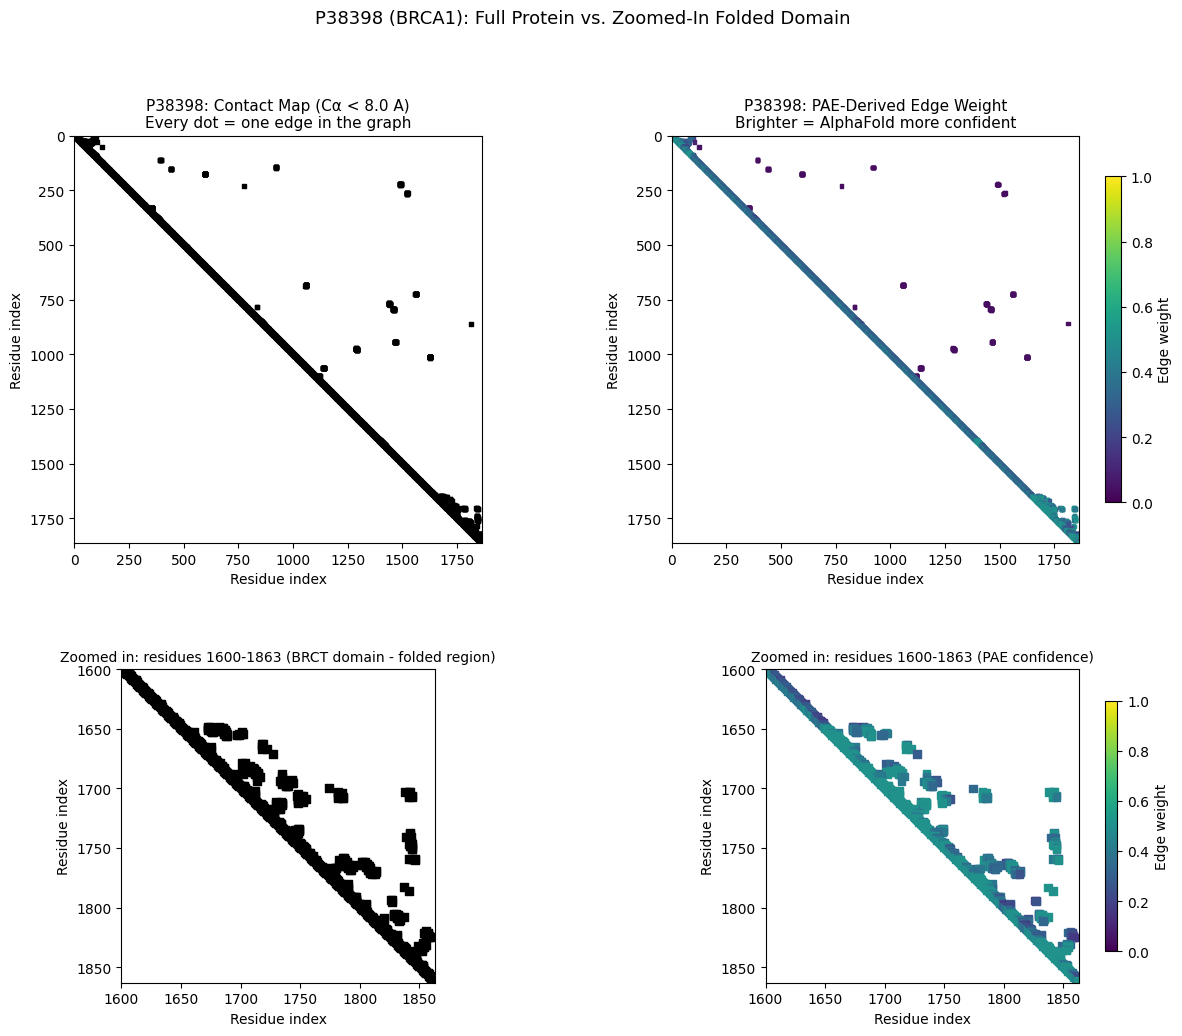

In [20]:
import matplotlib.pyplot as plt

example_id = "P38398"
g = torch.load(os.path.join(GRAPH_DIR, f"{example_id}.pt"), weights_only=False)
n = g.num_residues
src, dst = g.edge_index.numpy()
weights = g.edge_attr[:, 1].numpy()

# Only the upper triangle - each undirected contact is stored twice (i->j and j->i)
tri_mask = src < dst
src, dst, weights = src[tri_mask], dst[tri_mask], weights[tri_mask]

fig = plt.figure(figsize=(15, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1], hspace=0.35, wspace=0.25)

# --- Top row: full-protein overview. Scatter (not imshow) so sparse off-diagonal contacts stay visible ---
ax1 = fig.add_subplot(gs[0, 0])
ax1.scatter(dst, src, s=6, c="black", marker="s")
ax1.set_title(f"{example_id}: Contact Map (Cα < {DISTANCE_CUTOFF_ANGSTROM} A)\nEvery dot = one edge in the graph", fontsize=11)
ax1.set_xlabel("Residue index"); ax1.set_ylabel("Residue index")
ax1.set_xlim(0, n); ax1.set_ylim(n, 0); ax1.set_aspect("equal")

ax2 = fig.add_subplot(gs[0, 1])
sca = ax2.scatter(dst, src, s=6, c=weights, cmap="viridis", vmin=0, vmax=1, marker="s")
ax2.set_title(f"{example_id}: PAE-Derived Edge Weight\nBrighter = AlphaFold more confident", fontsize=11)
ax2.set_xlabel("Residue index"); ax2.set_ylabel("Residue index")
ax2.set_xlim(0, n); ax2.set_ylim(n, 0); ax2.set_aspect("equal")
plt.colorbar(sca, ax=ax2, shrink=0.8, label="Edge weight")

# --- Bottom row: zoomed into the BRCT domain (well-folded, C-terminal region) ---
ZOOM_START, ZOOM_END = 1600, 1863
zmask = (src >= ZOOM_START) & (src < ZOOM_END) & (dst >= ZOOM_START) & (dst < ZOOM_END)
zsrc, zdst, zweights = src[zmask], dst[zmask], weights[zmask]

ax3 = fig.add_subplot(gs[1, 0])
ax3.scatter(zdst, zsrc, s=30, c="black", marker="s")
ax3.set_title(f"Zoomed in: residues {ZOOM_START}-{ZOOM_END} (BRCT domain - folded region)", fontsize=10)
ax3.set_xlabel("Residue index"); ax3.set_ylabel("Residue index")
ax3.set_xlim(ZOOM_START, ZOOM_END); ax3.set_ylim(ZOOM_END, ZOOM_START); ax3.set_aspect("equal")

ax4 = fig.add_subplot(gs[1, 1])
sca2 = ax4.scatter(zdst, zsrc, s=30, c=zweights, cmap="viridis", vmin=0, vmax=1, marker="s")
ax4.set_title(f"Zoomed in: residues {ZOOM_START}-{ZOOM_END} (PAE confidence)", fontsize=10)
ax4.set_xlabel("Residue index"); ax4.set_ylabel("Residue index")
ax4.set_xlim(ZOOM_START, ZOOM_END); ax4.set_ylim(ZOOM_END, ZOOM_START); ax4.set_aspect("equal")
plt.colorbar(sca2, ax=ax4, shrink=0.8, label="Edge weight")

plt.suptitle(f"{example_id} (BRCA1): Full Protein vs. Zoomed-In Folded Domain", fontsize=13, y=0.995)
plt.show()


## 10. Visualizing a Local Graph Neighborhood (For a Non-Specialist Audience)
The full protein graph (1,863 nodes for BRCA1 alone) is too dense to draw in a way anyone could read. Instead, we zoom into the **immediate neighborhood of a single real variant**, the mutated residue itself, plus every residue directly connected to it (its 1-hop neighbors) to show concretely what a 'node' and an 'edge' actually are in this project.

**How to read this figure:**
- Each circle is one amino acid (a node), labelled with its identity and position (e.g. `C64` = Cysteine at position 64).
- The **red** circle is the variant position itself, this is the node the GNN will mark with the variant-site flag and substituted-residue identity described in Section 6.
- A line between two circles (an edge) means those two residues are within 8 Å of each other in the real 3D fold, note several of these neighbors are far apart in the sequence (e.g. residue 39 connecting to residue 64), which is only visible because we used the *3D structure*, not just the linear sequence.
- The **color and thickness** of each line is the PAE-derived confidence weight from Section 4, brighter/thicker = AlphaFold is more confident about that pair's relative position; darker/thinner = less confident. This is the literal quantity the GNN's message-passing will weight by.

In [15]:
!pip install networkx -q


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


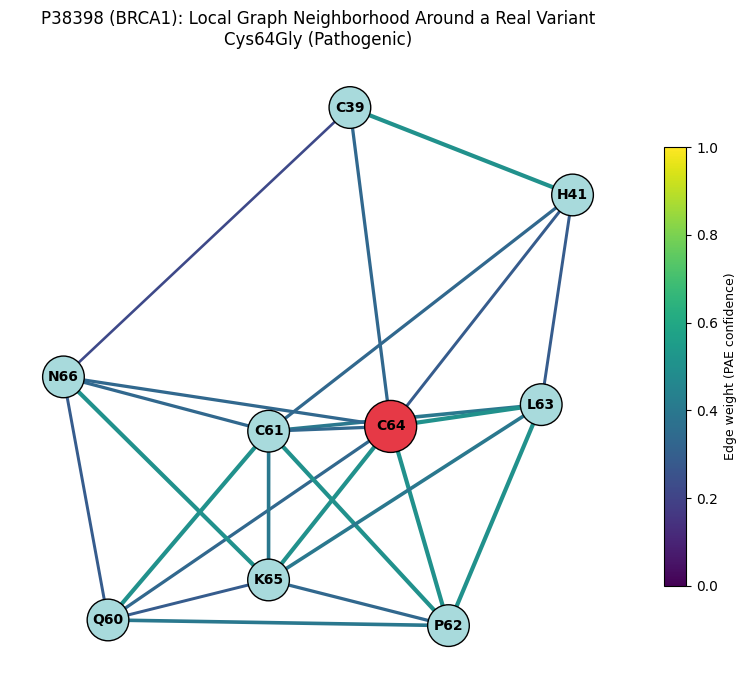

In [16]:
import networkx as nx

viz_uniprot_id = "P38398"  # BRCA1, consistent with earlier examples in this notebook
g_viz = torch.load(os.path.join(GRAPH_DIR, f"{viz_uniprot_id}.pt"), weights_only=False)
with open(os.path.join(META_DIR, f"{viz_uniprot_id}.json")) as f:
    viz_seq = json.load(f)["uniprotSequence"]

viz_variants = graph_ready_df[graph_ready_df["UniProt_ID"] == viz_uniprot_id]
example_variant = viz_variants[viz_variants["Target"] == 1].iloc[0]
center_node = int(example_variant["Pos"]) - 1

src, dst = g_viz.edge_index.numpy()
neighbors_1hop = (set(dst[src == center_node].tolist()) | set(src[dst == center_node].tolist())) - {center_node}
subgraph_nodes = sorted({center_node} | neighbors_1hop)

mask = np.isin(src, subgraph_nodes) & np.isin(dst, subgraph_nodes)
sub_src, sub_dst, sub_weights = src[mask], dst[mask], g_viz.edge_attr[mask, 1].numpy()

G = nx.Graph()
for n in subgraph_nodes:
    G.add_node(n, label=f"{viz_seq[n]}{n+1}")
for s, d, w in zip(sub_src, sub_dst, sub_weights):
    G.add_edge(int(s), int(d), weight=float(w))

pos = nx.spring_layout(G, seed=42, k=0.8)
node_colors = ["#E63946" if n == center_node else "#A8DADC" for n in G.nodes()]
node_sizes = [1400 if n == center_node else 900 for n in G.nodes()]
edge_weights_list = [G[u][v]["weight"] for u, v in G.edges()]
edge_widths = [1 + 4 * w for w in edge_weights_list]

plt.figure(figsize=(8, 7))
nx.draw_networkx_edges(G, pos, width=edge_widths, edge_color=edge_weights_list,
                        edge_cmap=plt.cm.viridis, edge_vmin=0, edge_vmax=1)
nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes, edgecolors="black")
nx.draw_networkx_labels(G, pos, labels=nx.get_node_attributes(G, "label"), font_size=10, font_weight="bold")
plt.title(
    f"{viz_uniprot_id} (BRCA1): Local Graph Neighborhood Around a Real Variant\n"
    f"{example_variant['Ref_AA']}{example_variant['Pos']}{example_variant['Alt_AA']} (Pathogenic)",
    fontsize=12
)
plt.axis("off")
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=0, vmax=1))
sm.set_array([])
cbar = plt.colorbar(sm, ax=plt.gca(), shrink=0.7)
cbar.set_label("Edge weight (PAE confidence)", fontsize=9)
plt.tight_layout()
plt.show()

## 11. Methods Summary (Copy-Paste for the Paper)
> Each protein was represented as a graph in which nodes correspond to individual amino acid residues and edges connect residue pairs within 8 Å (Cα-Cα distance) in the AlphaFold2-predicted structure. Node features combined a 1280-dimensional ESM-2 protein language model embedding with a one-hot encoding of wild-type residue identity. Edges were weighted by AlphaFold's Predicted Aligned Error (PAE) between the residue pair, transformed as 1/(1+PAE), so that the model could learn to discount structurally uncertain contacts rather than treating all spatial contacts as equally reliable, this PAE-weighting constitutes the central architectural novelty of this work relative to prior unweighted contact-graph approaches (e.g. gMVP). Each ClinVar missense variant was represented as an instance of its protein's shared structural graph, with the mutated node's feature vector augmented by a variant-site indicator and the substituted residue's one-hot identity, labelled with the variant's ClinVar pathogenicity classification.

**Supporting numbers to cite alongside this paragraph (filled in once this notebook has been run in full):**
- Cα distance cutoff: 8 Å
- ESM-2 checkpoint: `facebook/esm2_t33_650M_UR50D` (650M parameters, 1280-dim output)
- Node feature dimensionality: 1321 (1280 ESM-2 + 20 wild-type one-hot + 1 variant-site flag + 20 alt-residue one-hot)
- See `phase3_graph_manifest.csv` for per-protein graph-construction success rate, and the variant counts printed in Section 7 for the final `clinvar_graph_ready.csv` totals.